# Homework 2 — Problem 3:

In [2]:
import copy
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn

SEED = 0
np.random.seed(SEED); torch.manual_seed(SEED)

train = pd.read_csv("/Users/rohansivakumar/Desktop/AI:ML/DATA/train.csv")
val = pd.read_csv("/Users/rohansivakumar/Desktop/AI:ML/DATA/val.csv")
test = pd.read_csv("/Users/rohansivakumar/Desktop/AI:ML/DATA/test.csv")

Xtr, ytr = train[["x1", "x2"]].values, train["y"].values
Xva, yva = val[["x1", "x2"]].values, val["y"].values
Xte = test[["x1", "x2"]].values

## 3(a) — Visualize the training data

Left panel is a 2-D scatter of (x1, x2) coloured by y. Right panel has the same points in 3-D with y on the vertical axis.

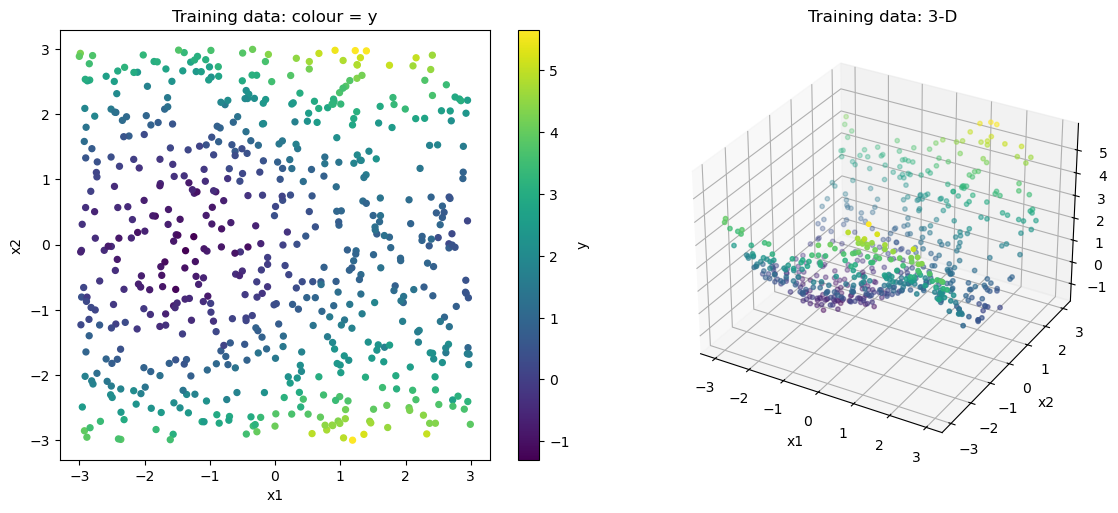

In [9]:
fig = plt.figure(figsize=(12, 5))
ax = fig.add_subplot(1, 2, 1)
sc = ax.scatter(Xtr[:, 0], Xtr[:, 1], c=ytr, cmap="viridis", s=18)
ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.set_title("Training data: colour = y"); ax.set_aspect("equal"); plt.colorbar(sc, ax=ax, label="y")
ax3 = fig.add_subplot(1, 2, 2, projection="3d")
ax3.scatter(Xtr[:, 0], Xtr[:, 1], ytr, c=ytr, cmap="viridis", s=10)
ax3.set_xlabel("x1"); ax3.set_ylabel("x2"); ax3.set_zlabel("y"); ax3.set_title("Training data: 3-D")
plt.tight_layout(); plt.show()

## 3(b)

best sigma = 3.467  (val MSE 0.0359)


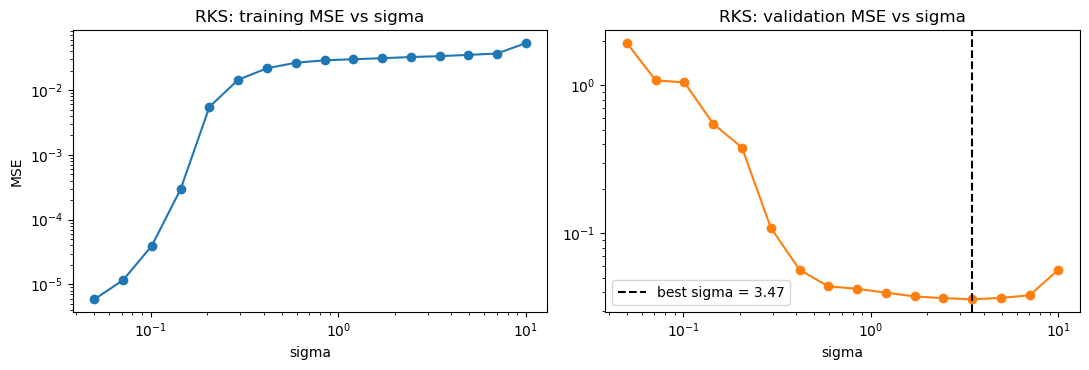

In [12]:
H, LAM = 1000, 1e-3
rng = np.random.default_rng(SEED)
W0 = rng.standard_normal((2, H))            # N(0, I); the actual frequencies are W0 / sigma
B = rng.uniform(0, 2 * np.pi, H)

def rks_features(X, sigma, W0=W0, B=B):
    A = X @ (W0 / sigma) + B
    return np.hstack([np.sin(A), np.cos(A)]) / np.sqrt(W0.shape[1])

def rks_fit(X, y, sigma, lam):
    Z = rks_features(X, sigma)
    y_bar = y.mean()
    w = np.linalg.solve(Z.T @ Z + lam * np.eye(Z.shape[1]), Z.T @ (y - y_bar))
    return dict(w=w, y_bar=y_bar, sigma=sigma)

def rks_predict(model, X):
    return rks_features(X, model["sigma"]) @ model["w"] + model["y_bar"]

mse = lambda a, b: float(np.mean((a - b) ** 2))

sigmas = np.logspace(-1.3, 1, 16)
rks_tr, rks_va = [], []
for s in sigmas:
    m = rks_fit(Xtr, ytr, s, LAM)
    rks_tr.append(mse(rks_predict(m, Xtr), ytr)); rks_va.append(mse(rks_predict(m, Xva), yva))

best_sigma = sigmas[int(np.argmin(rks_va))]
print(f"best sigma = {best_sigma:.3f}  (val MSE {min(rks_va):.4f})")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].semilogx(sigmas, rks_tr, "o-"); ax[0].set_title("RKS: training MSE vs sigma")
ax[1].semilogx(sigmas, rks_va, "o-", color="C1"); ax[1].axvline(best_sigma, ls="--", color="k", label=f"best sigma = {best_sigma:.2f}")
ax[1].set_title("RKS: validation MSE vs sigma"); ax[1].set_yscale("log"); ax[1].legend()
for a in ax: a.set_xlabel("sigma")
ax[0].set_ylabel("MSE"); ax[0].set_yscale("log")
plt.tight_layout(); plt.show()

Training MSE is monotonically increasing with σ, while validation MSE initially decreases, reaches a minimum at optimal σ = 3.47

## 3(c)

width    4  train MSE 0.2575  val MSE 0.2698
width    8  train MSE 0.1302  val MSE 0.1408
width   16  train MSE 0.0356  val MSE 0.0457
width   32  train MSE 0.0327  val MSE 0.0402
width   64  train MSE 0.0308  val MSE 0.0394
width  128  train MSE 0.0295  val MSE 0.0383
width  256  train MSE 0.0283  val MSE 0.0384
width  512  train MSE 0.0276  val MSE 0.0388
best width: 128


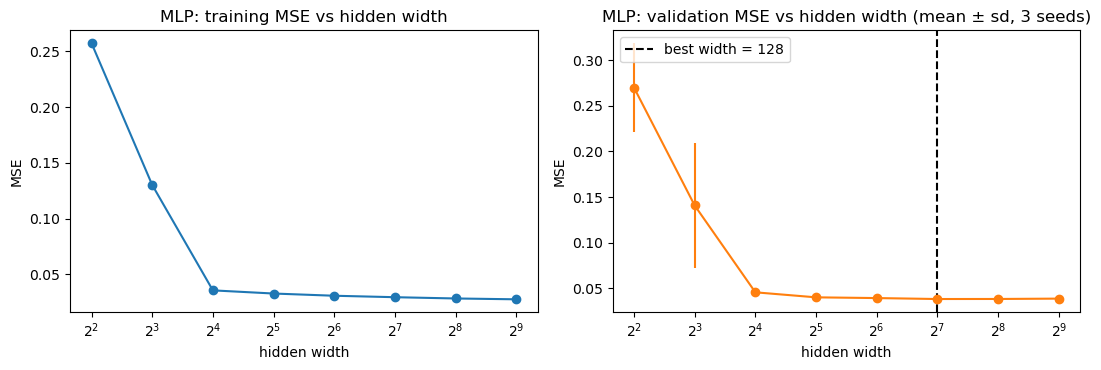

In [16]:
Ttr, Tytr = torch.tensor(Xtr, dtype=torch.float32), torch.tensor(ytr, dtype=torch.float32)
Tva, Tyva = torch.tensor(Xva, dtype=torch.float32), torch.tensor(yva, dtype=torch.float32)

def make_mlp(width):
    return nn.Sequential(nn.Linear(2, width), nn.ReLU(), nn.Linear(width, 1))

def train_mlp(width, seed, steps=2000, lr=1e-2):
    torch.manual_seed(seed)
    model = make_mlp(width)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=steps)
    for _ in range(steps):
        loss = ((model(Ttr).squeeze(-1) - Tytr) ** 2).mean()
        opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    with torch.no_grad():
        tr = ((model(Ttr).squeeze(-1) - Tytr) ** 2).mean().item()
        va = ((model(Tva).squeeze(-1) - Tyva) ** 2).mean().item()
    return model, tr, va

widths = [4, 8, 16, 32, 64, 128, 256, 512]
mlp_tr, mlp_va, mlp_va_sd = [], [], []
for w in widths:
    runs = [train_mlp(w, seed)[1:] for seed in range(3)]
    mlp_tr.append(np.mean([r[0] for r in runs])); mlp_va.append(np.mean([r[1] for r in runs])); mlp_va_sd.append(np.std([r[1] for r in runs]))
    print(f"width {w:4d}  train MSE {mlp_tr[-1]:.4f}  val MSE {mlp_va[-1]:.4f}")

best_width = widths[int(np.argmin(mlp_va))]
print("best width:", best_width)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].semilogx(widths, mlp_tr, "o-", base=2); ax[0].set_title("MLP: training MSE vs hidden width")
ax[1].errorbar(widths, mlp_va, yerr=mlp_va_sd, fmt="o-", color="C1"); ax[1].set_xscale("log", base=2)
ax[1].axvline(best_width, ls="--", color="k", label=f"best width = {best_width}"); ax[1].set_title("MLP: validation MSE vs hidden width (mean ± sd, 3 seeds)"); ax[1].legend()
for a in ax: a.set_xlabel("hidden width"); a.set_ylabel("MSE")
plt.tight_layout(); plt.show()

Based on validation MSE, the best configuration is an MLP with width 128 (val MSE: 0.0383)

## 3(d)

In [19]:
rks_best = rks_fit(Xtr, ytr, best_sigma, LAM)
rks_val_mse = mse(rks_predict(rks_best, Xva), yva)

cands = [train_mlp(best_width, seed) for seed in range(5)]
mlp_best, _, mlp_val_mse = min(cands, key=lambda t: t[2])

def mlp_predict(X):
    with torch.no_grad():
        return mlp_best(torch.tensor(X, dtype=torch.float32)).squeeze(-1).numpy()

print(f"RKS  (sigma={best_sigma:.3f}, D={2*H}, lambda={LAM}): validation MSE = {rks_val_mse:.4f}")
print(f"MLP  (width={best_width}):                     validation MSE = {mlp_val_mse:.4f}")

rks_test_pred, mlp_test_pred = rks_predict(rks_best, Xte), mlp_predict(Xte)
pd.DataFrame({"prediction": rks_test_pred}).to_csv("rks_test_predictions.csv", index=False)
pd.DataFrame({"prediction": mlp_test_pred}).to_csv("mlp_test_predictions.csv", index=False)
assert len(rks_test_pred) == len(mlp_test_pred) == len(test)
print("saved rks_test_predictions.csv and mlp_test_predictions.csv with", len(test), "rows each")

RKS  (sigma=3.467, D=2000, lambda=0.001): validation MSE = 0.0359
MLP  (width=128):                     validation MSE = 0.0379
saved rks_test_predictions.csv and mlp_test_predictions.csv with 200 rows each


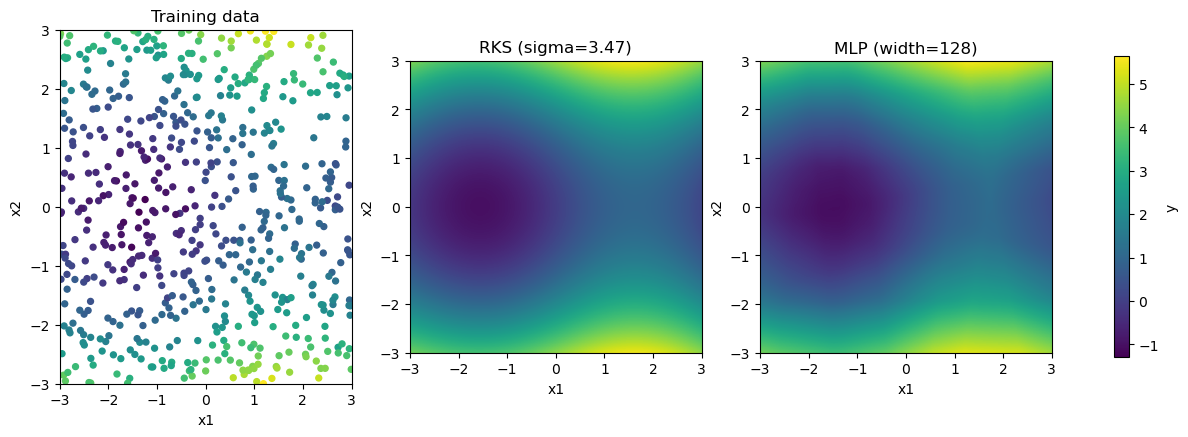

In [20]:
g = np.linspace(-3, 3, 200)
G1, G2 = np.meshgrid(g, g)
grid = np.column_stack([G1.ravel(), G2.ravel()])
surf_rks = rks_predict(rks_best, grid).reshape(G1.shape)
surf_mlp = mlp_predict(grid).reshape(G1.shape)
vmin, vmax = ytr.min(), ytr.max()

fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
ax[0].scatter(Xtr[:, 0], Xtr[:, 1], c=ytr, cmap="viridis", s=18, vmin=vmin, vmax=vmax); ax[0].set_title("Training data")
for a, S, t in [(ax[1], surf_rks, f"RKS (sigma={best_sigma:.2f})"), (ax[2], surf_mlp, f"MLP (width={best_width})")]:
    im = a.imshow(S, origin="lower", extent=[-3, 3, -3, 3], cmap="viridis", vmin=vmin, vmax=vmax); a.set_title(t)
for a in ax: a.set_xlabel("x1"); a.set_ylabel("x2"); a.set_xlim(-3, 3); a.set_ylim(-3, 3)
fig.colorbar(im, ax=ax, label="y", shrink=0.85)
plt.show()

The RKS model (sigma=3.467, D=2000, lambda=0.001) reports a validation MSE of 0.0359, while the MLP model (width=128) reports a validation MSE of 0.0379. These values are quite similar, and given the other validation MSE readings during hyperparameter selection, ~0.03 seems to be a "floor" of some sort, where neither model can perform better, and as a result they "tie" regarding this metric.
After some research, the RKS may perform slightly better due to the lack of optimization noise, and the randomly generated sinusoidal features create a smooth function. The MLP may run into problems due to the ReLU activation function creating a piecewise linear surface, as well as the fact that optimization occurs over a non-convex function. However, we can see that the MLP panel is as smooth as the RKS so, perhaps a width of 128 is too small to see any of the traditional kinks you'd find in a piecewise function.

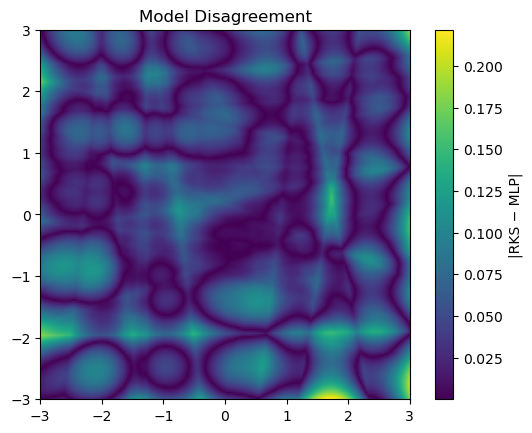

In [22]:
   plt.imshow(np.abs(surf_rks - surf_mlp), origin="lower", extent=[-3, 3, -3, 3], cmap="viridis")
   plt.colorbar(label="|RKS − MLP|"); plt.title("Model Disagreement"); plt.show()

Both models essentially produce the same smooth panel, with the minimum in the same place and the same maxima at the top and bottom edges, and they differ by at most about ~0.2, mostly near the edges where there isn't as much training data. Note the underlying function is simple and smooth, and both RKS and MLP are equipped to fit this fixed set of random smooth waves. Given data with a sharp/abrupt structure, the models would likely perform very differently.